# 01 - Qualité des données, EDA et validation statistique

**Projet PROJ-CS21 - Détection d'attaques réseau (CIC-IDS2017).**

Ce carnet est **exécuté** et ses sorties sont enregistrées. Il reproduit, sur des données versionnées dans le dépôt, les trois
premiers volets analytiques de l'application Streamlit :

1. **Contrôle qualité** : doublons, valeurs manquantes et infinies, types, valeurs impossibles, déséquilibre des classes ;
2. **EDA** : 12 figures (distributions, corrélations, profils de classes) ;
3. **Validation statistique formelle** : Chi-deux, ANOVA, Kruskal-Wallis, Shapiro-Wilk, Mann-Whitney U, avec correction de Holm et tailles d'effet.

Sources : `reports/inspection/` (faits mesurés sur les 2,8 millions de lignes brutes, script 01), `reports/eda/tables/` (script 02) et
`reports/app_data/analysis_sample.parquet` (échantillon plafonné par classe des données nettoyées, script 19).

In [1]:
import sys, logging, warnings
from pathlib import Path

ROOT = Path.cwd().resolve().parent if Path.cwd().name == "notebooks" else Path.cwd().resolve()
for p in (ROOT, ROOT / "src"):
    if str(p) not in sys.path:
        sys.path.insert(0, str(p))
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from config import settings
from nids.utils.logger import configure_logging
configure_logging(level="WARNING", log_to_file=False, force=True)

pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 200)
sns.set_theme(style="whitegrid", context="notebook")
print("Racine du projet :", ROOT)

Racine du projet : F:\DM_Project


## 1. Contrôle qualité

### 1.1 Les fichiers bruts (inspection, script 01)

In [2]:
import json
insp = json.loads((ROOT / "reports/inspection/inspection_summary.json").read_text(encoding="utf-8"))
profile = pd.read_csv(ROOT / "reports/inspection/column_profile.csv")
print(f"Lignes brutes          : {insp['n_rows']:,}")
print(f"Colonnes de variables  : {insp['n_feature_columns']}")
print(f"Doublons exacts        : {insp['duplicates']['n_duplicate_rows']:,} ({100*insp['duplicates']['n_duplicate_rows']/insp['n_rows']:.2f} %)")
print(f"Vecteurs contradictoires (même vecteur, deux labels) : {insp['duplicates']['n_conflicting_feature_vectors']:,}")
print(f"Cellules manquantes    : {insp['values']['n_missing']:,}   infinies : {insp['values']['n_infinite']:,}")
print(f"Colonnes constantes    : {insp['values']['constant_columns']}")
print(f"Labels mal encodés     : {insp['labels']['labels_with_odd_characters']}")
print("\nTypes des colonnes :")
print(profile['dtype'].value_counts().to_string())

Lignes brutes          : 2,830,743
Colonnes de variables  : 78
Doublons exacts        : 308,381 (10.89 %)
Vecteurs contradictoires (même vecteur, deux labels) : 698
Cellules manquantes    : 1,358   infinies : 4,376
Colonnes constantes    : ['Bwd PSH Flags', 'Bwd URG Flags', 'Fwd Avg Bytes/Bulk', 'Fwd Avg Packets/Bulk', 'Fwd Avg Bulk Rate', 'Bwd Avg Bytes/Bulk', 'Bwd Avg Packets/Bulk', 'Bwd Avg Bulk Rate']
Labels mal encodés     : ['Web Attack � Brute Force', 'Web Attack � Sql Injection', 'Web Attack � XSS']

Types des colonnes :
dtype
int64      54
float64    24


In [3]:
issues = profile[(profile.n_missing > 0) | (profile.n_inf > 0) | (profile.n_negative > 0) | profile.is_constant]
issues

,column,dtype,n_missing,n_inf,n_negative,n_unique,is_constant,min_finite,max_finite
1,Flow Duration,int64,0,0,115,1050899,False,-1.300000e+01,1.200000e+08
14,Flow Bytes/s,float64,1358,1509,85,1593908,False,-2.610000e+08,2.071000e+09
15,Flow Packets/s,float64,0,2867,115,1240164,False,-2.000000e+06,4.000000e+06
16,Flow IAT Mean,float64,0,0,115,1166311,False,-1.300000e+01,1.200000e+08
18,Flow IAT Max,int64,0,0,115,580289,False,-1.300000e+01,1.200000e+08
19,Flow IAT Min,int64,0,0,2891,136316,False,-1.400000e+01,1.200000e+08
24,Fwd IAT Min,int64,0,0,17,110631,False,-1.200000e+01,1.200000e+08
31,Bwd PSH Flags,int64,0,0,0,1,True,0.000000e+00,0.000000e+00
33,Bwd URG Flags,int64,0,0,0,1,True,0.000000e+00,0.000000e+00
34,Fwd Header Length,int64,0,0,35,3771,False,-3.221223e+10,4.644908e+06


**Lecture.** 10,9 % de doublons exacts, des taux infinis (`Flow Bytes/s`, `Flow Packets/s`) quand la durée du flux vaut 0, des
valeurs négatives impossibles (durées, longueurs d'en-tête) et 8 colonnes constantes. Le nettoyage (script 03) supprime les
doublons et les colonnes copiées, corrige les labels, et transforme les valeurs impossibles en **manquantes**, imputées ensuite par la
médiane **apprise sur l'apprentissage seulement** (dans le pipeline).

### 1.2 Contrôle de l'échantillon d'analyse (module `nids.data.quality`)

In [4]:
from nids.data import quality
sample = pd.read_parquet(ROOT / "reports/app_data/analysis_sample.parquet")
rep = quality.quality_report(sample)
print(f"{rep['n_rows']:,} lignes x {rep['n_columns']} colonnes ({rep['n_numeric']} numériques), {rep['memory_mb']:.1f} Mo")
print("Doublons :", rep["duplicates"])
print("Constats :")
for i in rep["issues"]:
    print("  -", i)

22,143 lignes x 68 colonnes (66 numériques), 14.3 Mo
Doublons : {'n_rows': 22143, 'n_duplicate_rows': 0, 'n_duplicate_feature_vectors': 0, 'n_conflicting_feature_vectors': 0, 'pct_duplicate_rows': 0.0}
Constats :
  - 24 missing cells in 3 column(s)
  - 3 constant column(s): Bwd PSH Flags, Fwd URG Flags, RST Flag Count
  - strong class imbalance (largest / smallest class = 182)


In [5]:
rep["balance"]

,class,rows,share_pct,ratio_to_largest
0,BENIGN,2000,9.032200,1.000000
1,DDoS,2000,9.032200,1.000000
2,DoS GoldenEye,2000,9.032200,1.000000
3,DoS Slowhttptest,2000,9.032200,1.000000
4,DoS Hulk,2000,9.032200,1.000000
5,DoS slowloris,2000,9.032200,1.000000
6,FTP-Patator,2000,9.032200,1.000000
7,SSH-Patator,2000,9.032200,1.000000
8,PortScan,2000,9.032200,1.000000
9,Bot,1953,8.819943,1.024066


L'échantillon vient des données **nettoyées** : il n'a plus de doublons ni d'infinis. Il garde toutes les lignes des petites classes
(Heartbleed 11, Sql Injection 21, Infiltration 36) et plafonne les grandes à 2 000 lignes. Il ne représente donc **pas** le vrai mélange
de trafic (83 % BENIGN), mais il rend les attaques rares visibles pour l'EDA et les tests.

## 2. Analyse exploratoire (12 figures)

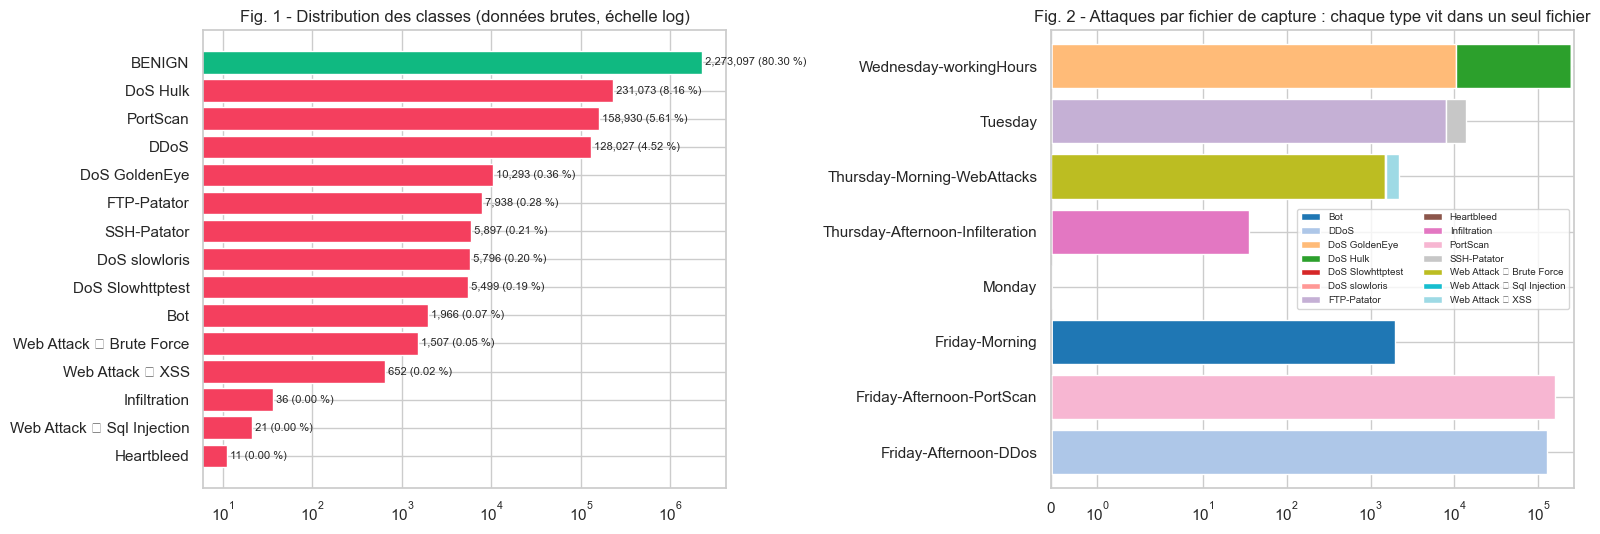

In [6]:
labels = pd.read_csv(ROOT / "reports/eda/tables/label_distribution.csv")
by_file = pd.read_csv(ROOT / "reports/eda/tables/label_by_file.csv").set_index("Label")
fig, axes = plt.subplots(1, 2, figsize=(16, 5.5))
ax = axes[0]
colors = ["#10b981" if l == "BENIGN" else "#f43f5e" for l in labels["label"]]
ax.barh(labels["label"], labels["count"], color=colors); ax.set_xscale("log"); ax.invert_yaxis()
ax.set_title("Fig. 1 - Distribution des classes (données brutes, échelle log)")
for y, (c, p) in enumerate(zip(labels["count"], labels["percent"])):
    ax.text(c, y, f" {c:,} ({p:.2f} %)", va="center", fontsize=8)
ax = axes[1]
share = by_file.drop(index="BENIGN").T
share.index = [i.replace(".pcap_ISCX.csv", "").replace("-WorkingHours", "") for i in share.index]
share.plot(kind="barh", stacked=True, ax=ax, colormap="tab20", width=0.8)
ax.set_xscale("symlog"); ax.legend(fontsize=7, ncol=2); ax.set_title("Fig. 2 - Attaques par fichier de capture : chaque type vit dans un seul fichier")
plt.tight_layout(); plt.show()

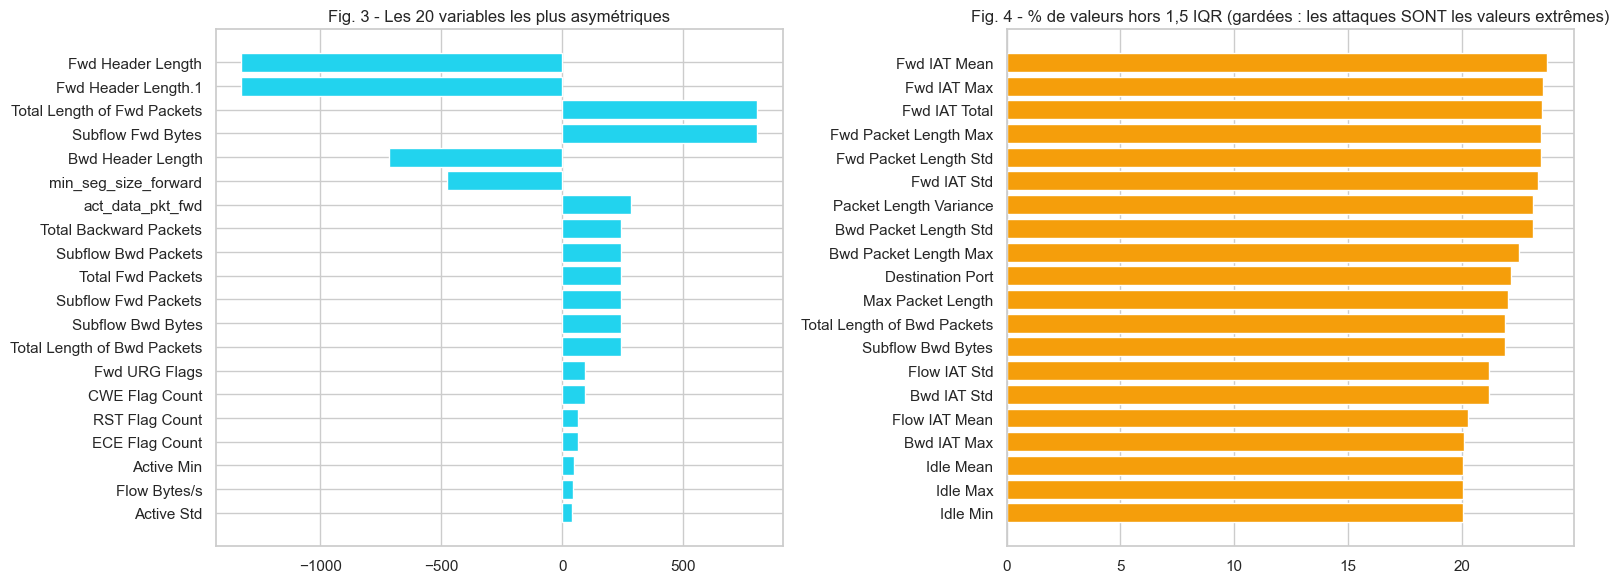

In [7]:
desc = pd.read_csv(ROOT / "reports/eda/tables/descriptive_statistics.csv")
out = pd.read_csv(ROOT / "reports/eda/tables/outlier_summary.csv")
fig, axes = plt.subplots(1, 2, figsize=(16, 6))
top = desc.assign(a=desc.skewness.abs()).nlargest(20, "a")
axes[0].barh(top["column"], top["skewness"], color="#22d3ee"); axes[0].invert_yaxis()
axes[0].set_title("Fig. 3 - Les 20 variables les plus asymétriques")
top = out.nlargest(20, "outlier_percent")
axes[1].barh(top["column"], top["outlier_percent"], color="#f59e0b"); axes[1].invert_yaxis()
axes[1].set_title("Fig. 4 - % de valeurs hors 1,5 IQR (gardées : les attaques SONT les valeurs extrêmes)")
plt.tight_layout(); plt.show()

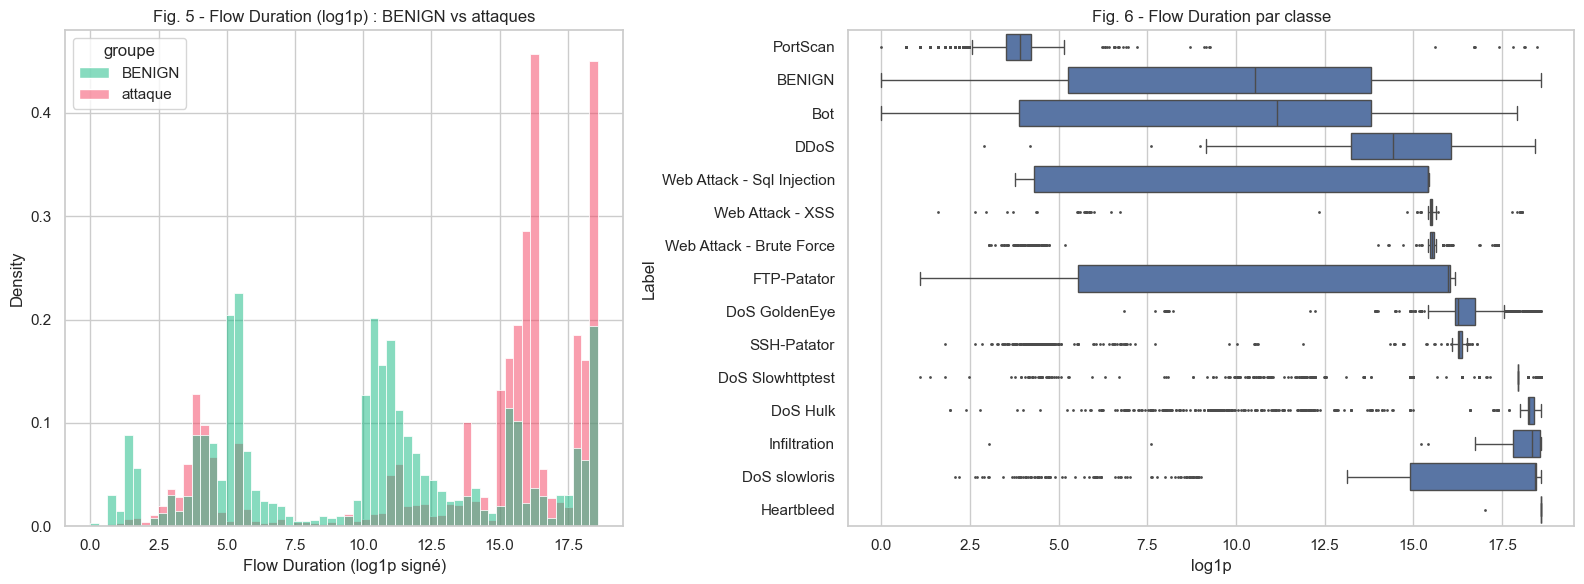

In [8]:
LABEL = settings.LABEL_COLUMN
slog = lambda s: np.sign(s) * np.log1p(np.abs(s))
feat = "Flow Duration"
d = sample[[feat, LABEL]].replace([np.inf, -np.inf], np.nan).dropna()
d["log"] = slog(d[feat]); d["groupe"] = np.where(d[LABEL] == "BENIGN", "BENIGN", "attaque")
fig, axes = plt.subplots(1, 2, figsize=(16, 6), gridspec_kw={"width_ratios": [1, 1.3]})
sns.histplot(d, x="log", hue="groupe", bins=60, stat="density", common_norm=False, ax=axes[0], palette={"BENIGN": "#10b981", "attaque": "#f43f5e"})
axes[0].set_title(f"Fig. 5 - {feat} (log1p) : BENIGN vs attaques"); axes[0].set_xlabel(f"{feat} (log1p signé)")
order = d.groupby(LABEL)["log"].median().sort_values().index
sns.boxplot(d, x="log", y=LABEL, order=order, ax=axes[1], fliersize=1)
axes[1].set_title(f"Fig. 6 - {feat} par classe"); axes[1].set_xlabel("log1p")
plt.tight_layout(); plt.show()

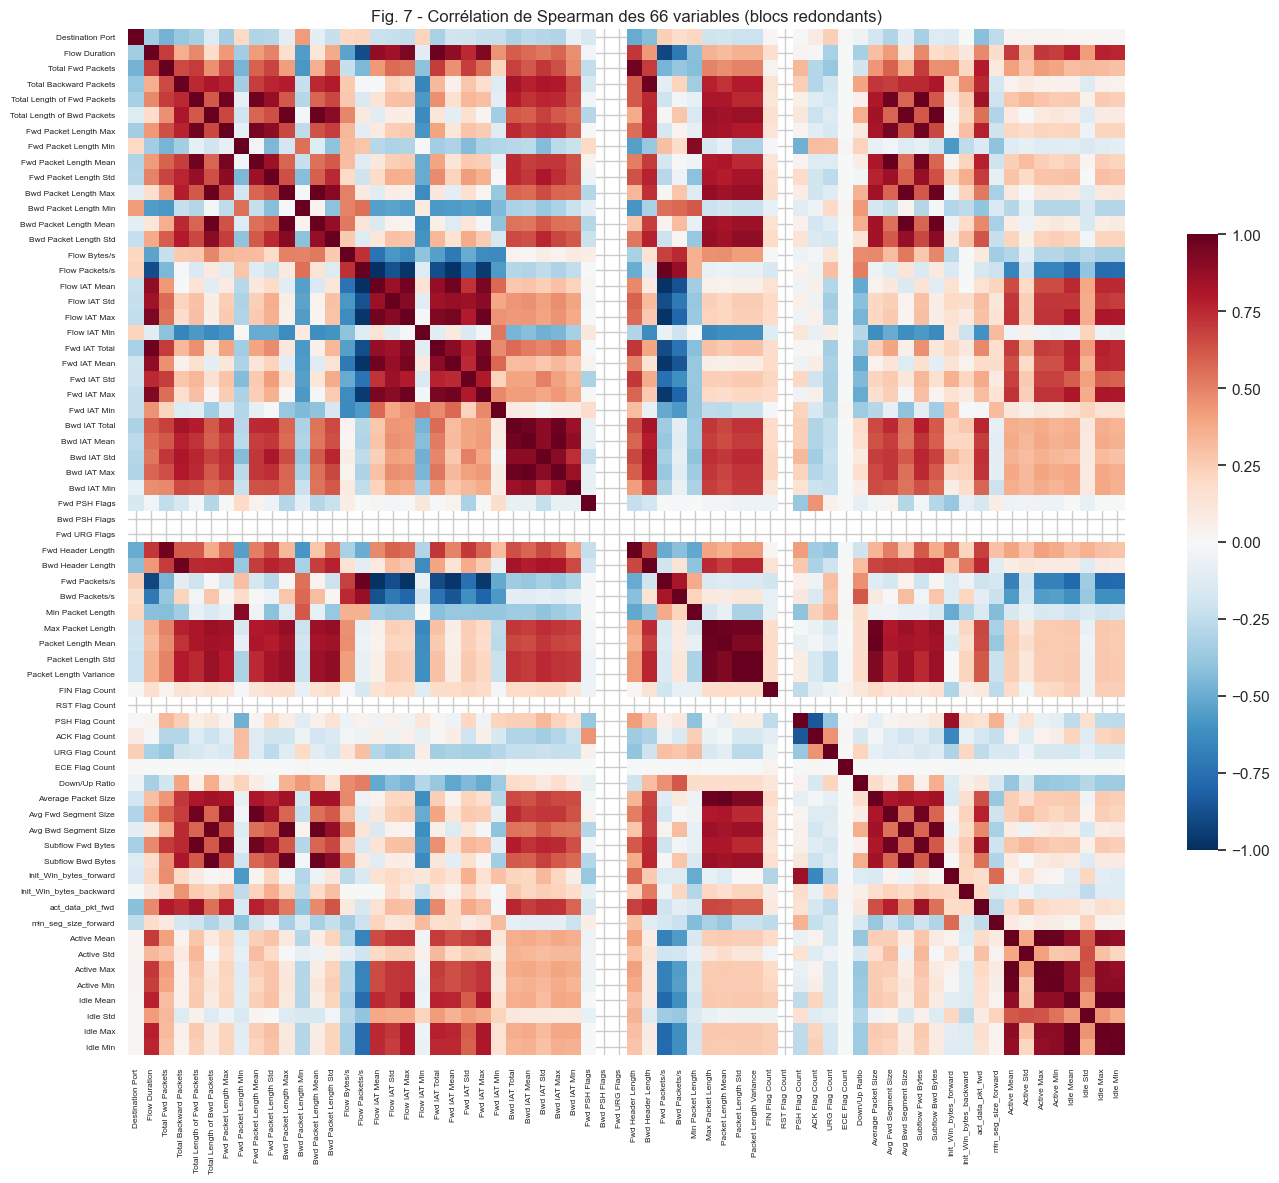

41 paires avec |r| >= 0.95 sur les données complètes -> filtre de corrélation du pipeline


In [9]:
feats = [c for c in sample.columns if c not in (LABEL, settings.SOURCE_FILE_COLUMN)]
corr = sample[feats].replace([np.inf, -np.inf], np.nan).corr(method="spearman")
fig, ax = plt.subplots(figsize=(14, 12))
sns.heatmap(corr, cmap="RdBu_r", vmin=-1, vmax=1, ax=ax, xticklabels=True, yticklabels=True, cbar_kws={"shrink": .6})
ax.tick_params(labelsize=6); ax.set_title("Fig. 7 - Corrélation de Spearman des 66 variables (blocs redondants)")
plt.tight_layout(); plt.show()
pairs = pd.read_csv(ROOT / "reports/eda/tables/high_correlation_pairs.csv")
print(f"{(pairs.correlation.abs() >= settings.CORRELATION_THRESHOLD).sum()} paires avec |r| >= {settings.CORRELATION_THRESHOLD} sur les données complètes -> filtre de corrélation du pipeline")

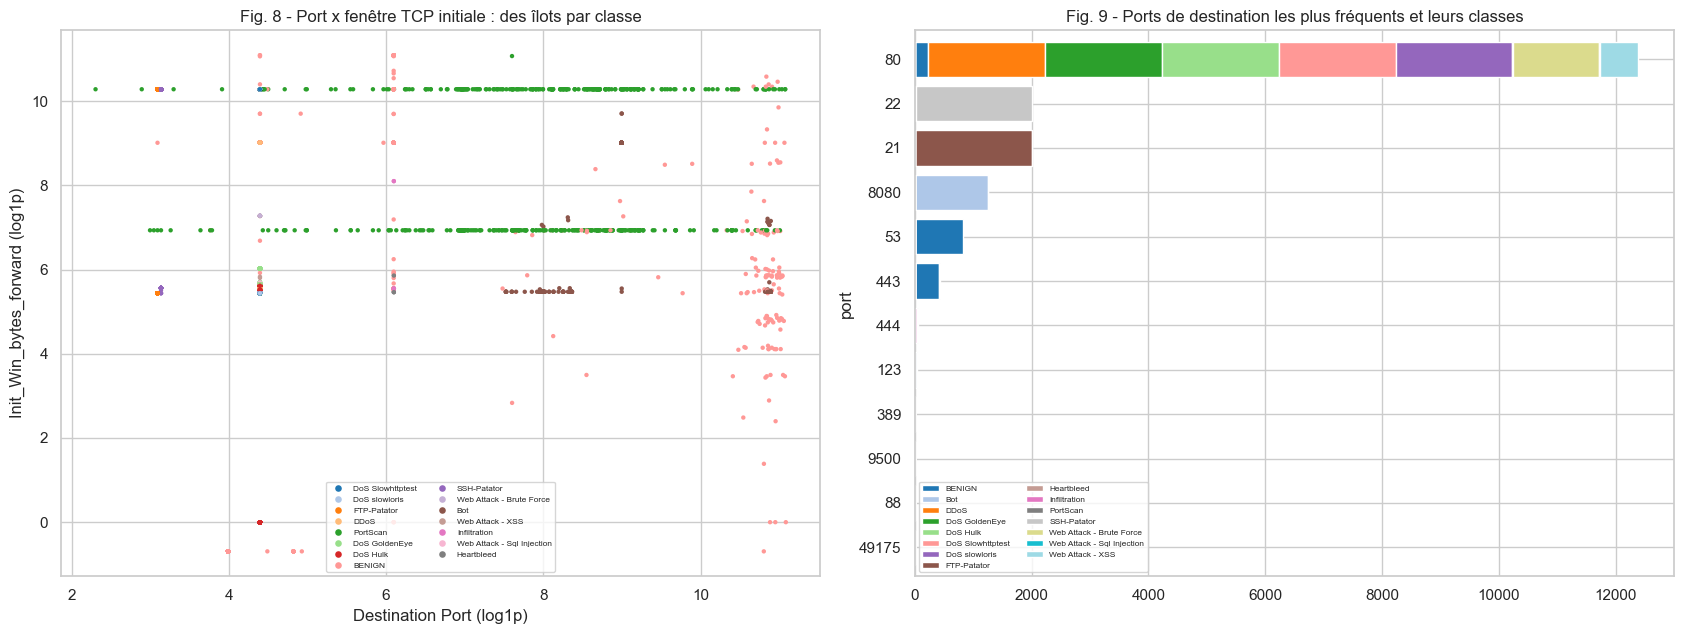

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(17, 6.5))
pts = sample.sample(n=min(len(sample), 6000), random_state=0)
sns.scatterplot(x=slog(pts["Destination Port"]), y=slog(pts["Init_Win_bytes_forward"]), hue=pts[LABEL], s=10, ax=axes[0], palette="tab20", linewidth=0)
axes[0].legend(fontsize=6, markerscale=1.5, ncol=2); axes[0].set_xlabel("Destination Port (log1p)"); axes[0].set_ylabel("Init_Win_bytes_forward (log1p)")
axes[0].set_title("Fig. 8 - Port x fenêtre TCP initiale : des îlots par classe")
ports = sample.assign(port=sample["Destination Port"].astype(int).astype(str))
top = ports["port"].value_counts().head(12).index
ct = pd.crosstab(ports.loc[ports.port.isin(top), "port"], ports.loc[ports.port.isin(top), LABEL])
ct.loc[ct.sum(axis=1).sort_values().index].plot(kind="barh", stacked=True, ax=axes[1], colormap="tab20", width=0.8)
axes[1].legend(fontsize=6, ncol=2); axes[1].set_title("Fig. 9 - Ports de destination les plus fréquents et leurs classes")
plt.tight_layout(); plt.show()

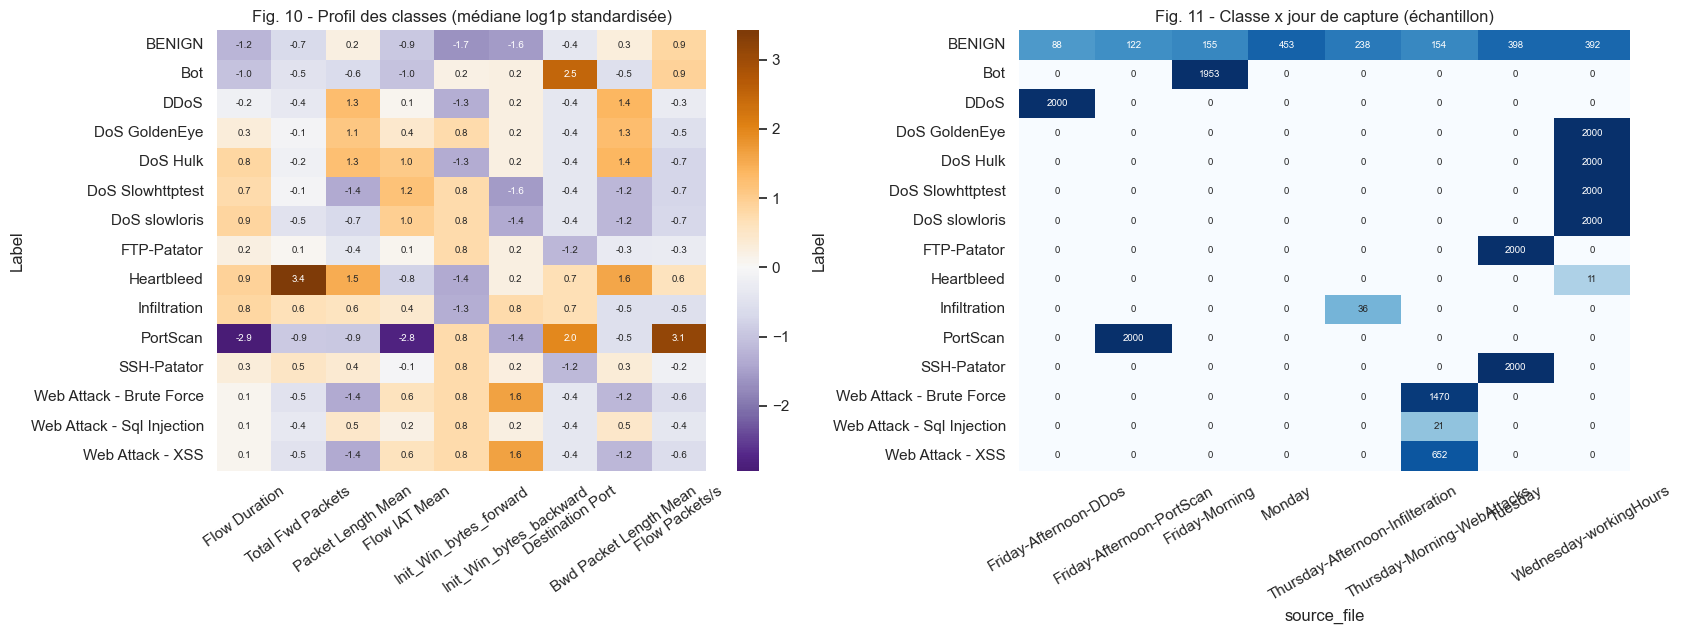

In [11]:
prof = ["Flow Duration", "Total Fwd Packets", "Packet Length Mean", "Flow IAT Mean", "Init_Win_bytes_forward", "Init_Win_bytes_backward", "Destination Port", "Bwd Packet Length Mean", "Flow Packets/s"]
med = slog(sample.groupby(LABEL)[prof].median())
z = (med - med.mean()) / med.std(ddof=0)
fig, axes = plt.subplots(1, 2, figsize=(17, 6.5))
sns.heatmap(z, cmap="PuOr_r", center=0, annot=True, fmt=".1f", annot_kws={"size": 7}, ax=axes[0])
axes[0].set_title("Fig. 10 - Profil des classes (médiane log1p standardisée)"); axes[0].tick_params(axis="x", rotation=35)
day = pd.crosstab(sample[LABEL], sample[settings.SOURCE_FILE_COLUMN].str.replace(".pcap_ISCX.csv", "").str.replace("-WorkingHours", ""))
sns.heatmap(np.log10(day + 1), cmap="Blues", ax=axes[1], annot=day, fmt="d", annot_kws={"size": 7}, cbar=False)
axes[1].set_title("Fig. 11 - Classe x jour de capture (échantillon)"); axes[1].tick_params(axis="x", rotation=30)
plt.tight_layout(); plt.show()

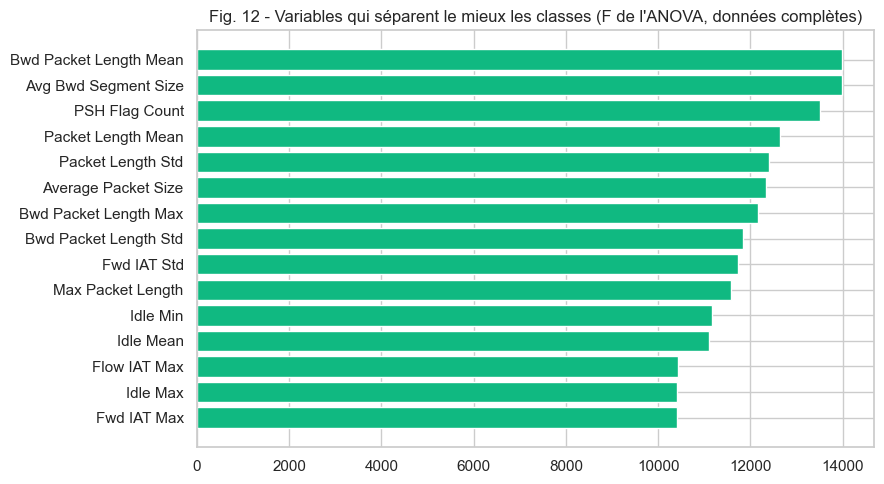

In [12]:
sep = pd.read_csv(ROOT / "reports/eda/tables/feature_class_separation.csv").dropna().nlargest(15, "f_statistic")
fig, ax = plt.subplots(figsize=(9, 5))
ax.barh(sep["column"], sep["f_statistic"], color="#10b981"); ax.invert_yaxis()
ax.set_title("Fig. 12 - Variables qui séparent le mieux les classes (F de l'ANOVA, données complètes)")
plt.tight_layout(); plt.show()

**Ce que montrent les figures.** (1) Fort déséquilibre : BENIGN 80 %, trois classes sous 40 flux, d'où le macro F1 comme
métrique principale. (2) Chaque type d'attaque provient d'un seul jour, donc un découpage aléatoire est optimiste (testé au script 15).
(3-4) Asymétrie extrême et nombreuses valeurs extrêmes, ce qui justifie le log1p signé et la médiane. (5-6, 8-10) Les classes diffèrent
fortement sur les ports, les fenêtres TCP, les durées et les inter-arrivées. (7) De nombreuses variables redondantes, retirées par
le filtre de corrélation.

## 3. Validation statistique formelle

Cinq tests distincts sur **chacune** des 66 variables (module `nids.eda.stat_tests`). Avec des milliers de lignes, presque toutes les
p-valeurs sont minuscules : on corrige par **Holm** (66 tests par famille) et on conclut sur les **tailles d'effet**.

| Test | H0 | Taille d'effet |
|---|---|---|
| Chi-deux | variable discrétisée (quantiles) et classe indépendantes | V de Cramér |
| ANOVA à un facteur | même moyenne dans toutes les classes | eta² |
| Kruskal-Wallis | même distribution dans toutes les classes | epsilon² |
| Shapiro-Wilk | la variable suit une loi normale | W |
| Mann-Whitney U | même distribution BENIGN et attaques | corrélation bisériale de rang r |

In [13]:
from nids.eda import stat_tests as T
features = [c for c in sample.columns if c not in (LABEL, settings.SOURCE_FILE_COLUMN)]
results = T.run_all_tests(sample, features)
T.summary_table(results)

,test,title,features_tested,reject_h0_holm,large_effect,top_feature
0,chi2,Chi-square test of independence (binned featur...,58,57,56,Destination Port
1,anova,One-way ANOVA (class means),63,62,51,Subflow Bwd Bytes
2,kruskal,Kruskal-Wallis H test (class distributions),63,62,62,Destination Port
3,shapiro,Shapiro-Wilk normality test,62,62,0,Total Length of Bwd Packets
4,mannwhitney,Mann-Whitney U test (BENIGN vs attack),63,56,2,Init_Win_bytes_forward


### 3.1 Shapiro-Wilk : normalité

H0 (normalité) rejetée pour 62 / 62 variables
W médian : 0.347 (brut)  ->  0.782 (après log1p signé)


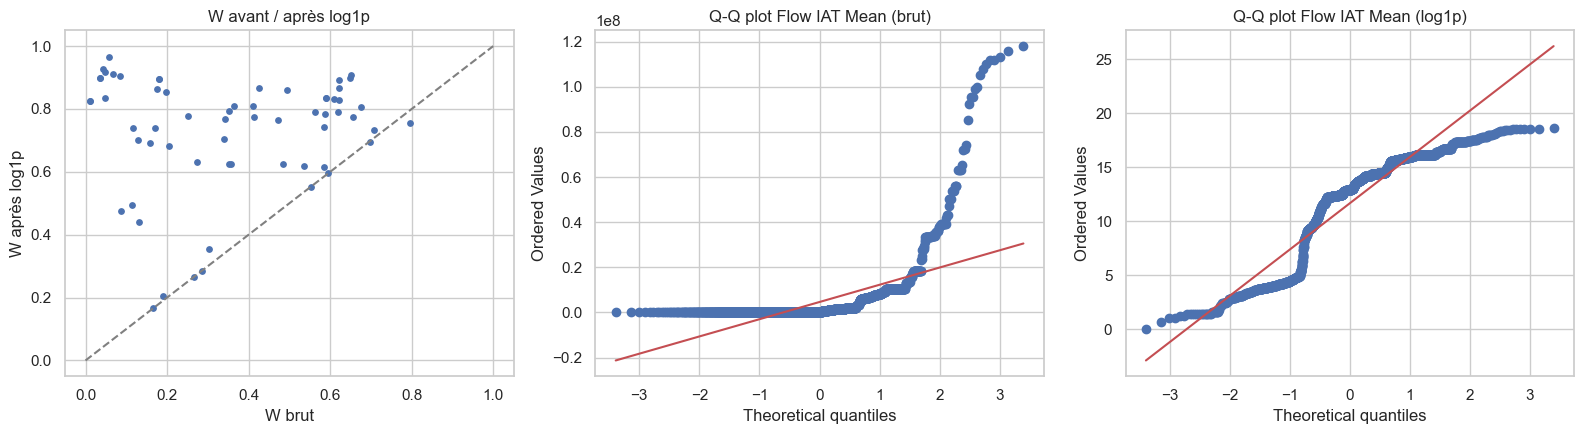

,feature,statistic,statistic_log,skewness,p_holm
0,Total Length of Bwd Packets,0.010454,0.824855,69.651524,8.223590e-94
1,Subflow Bwd Bytes,0.010454,0.824855,69.651524,8.223590e-94
2,Subflow Fwd Bytes,0.034396,0.899468,50.339958,3.015524e-93
3,Total Length of Fwd Packets,0.034396,0.899468,50.339958,3.015524e-93
4,Flow Bytes/s,0.042482,0.926889,44.661342,4.600997e-93
5,act_data_pkt_fwd,0.047021,0.836276,62.799705,5.850723e-93
6,Total Fwd Packets,0.048841,0.917836,44.691379,6.375783e-93
7,Fwd Header Length,0.056626,0.966997,48.348154,9.773931e-93


In [14]:
sh = results["shapiro"]
print(f"H0 (normalité) rejetée pour {int(sh.reject_h0.sum())} / {int(sh.p_value.notna().sum())} variables")
print(f"W médian : {sh.statistic.median():.3f} (brut)  ->  {sh.statistic_log.median():.3f} (après log1p signé)")
from scipy import stats as sps
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
axes[0].scatter(sh.statistic, sh.statistic_log, s=15); axes[0].plot([0, 1], [0, 1], "--", c="grey")
axes[0].set(xlabel="W brut", ylabel="W après log1p", title="W avant / après log1p")
v = sample["Flow IAT Mean"].replace([np.inf, -np.inf], np.nan).dropna().sample(2000, random_state=0)
sps.probplot(v, plot=axes[1]); axes[1].set_title("Q-Q plot Flow IAT Mean (brut)")
sps.probplot(slog(v), plot=axes[2]); axes[2].set_title("Q-Q plot Flow IAT Mean (log1p)")
plt.tight_layout(); plt.show()
sh[["feature", "statistic", "statistic_log", "skewness", "p_holm"]].head(8)

Aucune variable n'est normale, même après log1p. Les hypothèses de l'ANOVA ne tiennent donc pas : on la garde à titre indicatif et on
prend **Kruskal-Wallis** comme test de référence.

### 3.2 Kruskal-Wallis et ANOVA : les classes diffèrent-elles ?

In [15]:
kw, an = results["kruskal"], results["anova"]
both = kw.merge(an[["feature", "effect_size"]], on="feature", suffixes=("_kw", "_anova"))
rho = both[["effect_size_kw", "effect_size_anova"]].corr(method="spearman").iloc[0, 1]
print(f"Kruskal-Wallis : H0 rejetée pour {int(kw.reject_h0.sum())} variables, effet fort pour {int((kw.effect == 'large').sum())}")
print(f"ANOVA          : H0 rejetée pour {int(an.reject_h0.sum())} variables")
print(f"Accord des classements (Spearman entre epsilon² et eta²) : {rho:.2f}")
kw[["feature", "statistic", "dof", "p_holm", "effect_size", "effect"]].head(10)

Kruskal-Wallis : H0 rejetée pour 62 variables, effet fort pour 62
ANOVA          : H0 rejetée pour 62 variables
Accord des classements (Spearman entre epsilon² et eta²) : 0.38


,feature,statistic,dof,p_holm,effect_size,effect
0,Destination Port,18530.274410,14,0.0,0.836883,large
1,Bwd Packet Length Min,14878.549229,14,0.0,0.671960,large
2,Flow IAT Mean,13998.191317,14,0.0,0.632201,large
3,Flow Packets/s,13960.605574,14,0.0,0.630731,large
4,min_seg_size_forward,13558.286116,14,0.0,0.612333,large
5,Bwd Packets/s,13450.277923,14,0.0,0.607455,large
6,Fwd Packets/s,13428.318759,14,0.0,0.606464,large
7,Flow IAT Max,13112.978685,14,0.0,0.592222,large
8,Fwd IAT Mean,12949.447635,14,0.0,0.584836,large
9,Flow Duration,12570.773804,14,0.0,0.567734,large


Les deux tests rejettent H0 pour les **mêmes** variables, donc cette conclusion ne dépend pas de l'hypothèse de normalité. En revanche, leurs classements par taille d'effet ne concordent que modérément (ρ de Spearman ci-dessus) : eta² compare des **moyennes**, que quelques flux extrêmes dominent, alors qu'epsilon² compare des **rangs**. On retient le classement de Kruskal-Wallis.

### 3.3 Chi-deux d'indépendance

In [16]:
ch = results["chi2"]
print(f"Indépendance rejetée pour {int(ch.reject_h0.sum())} variables ; V de Cramér fort pour {int((ch.effect == 'large').sum())}")
ch[["feature", "statistic", "dof", "p_holm", "effect_size", "effect", "note"]].head(10)

Indépendance rejetée pour 57 variables ; V de Cramér fort pour 56


,feature,statistic,dof,p_holm,effect_size,effect,note
0,Destination Port,43466.041778,42,0.0,0.808903,large,4 bins x 15 classes; 12% of expected counts < 5
1,Bwd Packet Length Max,40104.591869,42,0.0,0.776995,large,4 bins x 15 classes; 12% of expected counts < 5
2,Bwd Packet Length Std,26041.569099,28,0.0,0.766832,large,3 bins x 15 classes; 9% of expected counts < 5
3,Bwd Packet Length Mean,38628.416446,42,0.0,0.762561,large,4 bins x 15 classes; 12% of expected counts < 5
4,Avg Bwd Segment Size,38628.416446,42,0.0,0.762561,large,4 bins x 15 classes; 12% of expected counts < 5
5,Init_Win_bytes_backward,48771.094816,56,0.0,0.742050,large,5 bins x 15 classes; 13% of expected counts < 5
6,Max Packet Length,35717.202141,42,0.0,0.733263,large,4 bins x 15 classes; 12% of expected counts < 5
7,Subflow Bwd Bytes,35713.055404,42,0.0,0.733221,large,4 bins x 15 classes; 10% of expected counts < 5
8,Total Length of Bwd Packets,35713.055404,42,0.0,0.733221,large,4 bins x 15 classes; 10% of expected counts < 5
9,Packet Length Std,35694.081688,42,0.0,0.733026,large,4 bins x 15 classes; 12% of expected counts < 5


### 3.4 Mann-Whitney U : BENIGN vs attaques

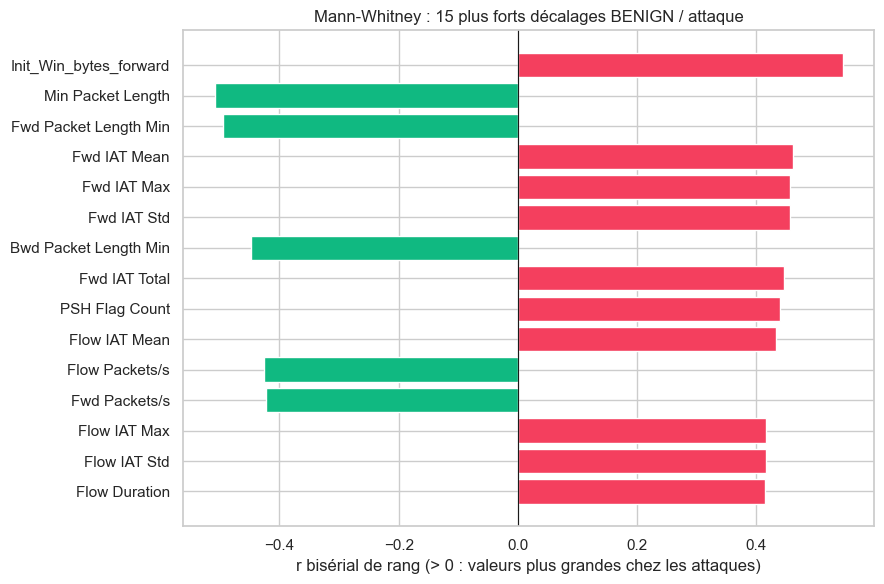

,feature,statistic,p_holm,effect_size,effect,note
0,Init_Win_bytes_forward,9177390.0,0.000000e+00,0.544388,large,median BENIGN 118 vs attack 2.92e+04
1,Min Packet Length,30386862.5,0.000000e+00,-0.508557,large,median BENIGN 6 vs attack 0
2,Fwd Packet Length Min,30113304.5,0.000000e+00,-0.494976,medium,median BENIGN 6 vs attack 0
3,Fwd IAT Mean,10859248.5,1.462651e-253,0.460892,medium,median BENIGN 4 vs attack 7.918e+05
4,Fwd IAT Max,10955785.5,2.509079e-248,0.456100,medium,median BENIGN 4 vs attack 3.151e+06
5,Fwd IAT Std,10958087.0,1.462651e-253,0.455985,medium,median BENIGN 0 vs attack 9.395e+05
6,Bwd Packet Length Min,29174175.0,0.000000e+00,-0.448353,medium,median BENIGN 6 vs attack 0
7,Fwd IAT Total,11156568.0,1.290977e-237,0.446132,medium,median BENIGN 4 vs attack 5.777e+06
8,PSH Flag Count,11289965.5,0.000000e+00,0.439509,medium,median BENIGN 0 vs attack 1
9,Flow IAT Mean,11438672.5,6.197260e-222,0.432127,medium,median BENIGN 1.622e+04 vs attack 4.916e+05


In [17]:
mw = results["mannwhitney"]
fig, ax = plt.subplots(figsize=(9, 6))
t = mw.dropna(subset=["effect_size"]).head(15).iloc[::-1]
ax.barh(t.feature, t.effect_size, color=["#f43f5e" if v > 0 else "#10b981" for v in t.effect_size])
ax.axvline(0, c="k", lw=.8); ax.set(xlabel="r bisérial de rang (> 0 : valeurs plus grandes chez les attaques)", title="Mann-Whitney : 15 plus forts décalages BENIGN / attaque")
plt.tight_layout(); plt.show()
mw[["feature", "statistic", "p_holm", "effect_size", "effect", "note"]].head(10)

## Conclusions

* **Qualité** : doublons, infinis, valeurs impossibles et labels corrompus ont été identifiés et traités. Les 698 vecteurs
  contradictoires sont un plancher d'erreur irréductible.
* **Normalité** : rejetée partout (Shapiro-Wilk), ce qui justifie le log1p signé, la médiane plutôt que la moyenne pour l'imputation,
  et les tests non paramétriques.
* **Dépendance à la classe** : presque toutes les variables dépendent de la classe (Kruskal-Wallis, Chi-deux), souvent avec un effet fort.
  La tâche supervisée est donc apprenable. `Destination Port` arrive en tête, ce qui relie au test d'ablation du port (script 14).
* **BENIGN vs attaque** : les décalages (Mann-Whitney) sont plus faibles qu'entre types d'attaque. Un seuil sur une seule variable
  ne suffit pas, il faut des modèles multivariés (carnet 02).
* **Limite** : les flux d'une même session d'attaque ne sont pas indépendants, donc les p-valeurs sont optimistes. Les tailles d'effet
  sont la partie robuste.